# Homework 2: emissions and trade

The question and submission instructions are in `assignment.pdf`.

`data/co2_2023.csv` contains one country per row for 2023, with population and territorial and consumption-based CO2 emissions. The estimates come from Our World in Data and the Global Carbon Budget. `data/countries.geojson` contains Natural Earth country names, identifiers and boundary geometries. Definitions and sources are in `data/README.md`.

In [1]:
import pandas as pd

emissions = pd.read_csv("data/co2_2023.csv")
emissions.head()

,country,iso_code,year,population,co2,co2_per_capita,consumption_co2,consumption_co2_per_capita
0,Afghanistan,AFG,2023,41454762.0,10.516,0.254,NaN,NaN
1,Albania,ALB,2023,2811660.0,4.417,1.571,5.382,1.914
2,Algeria,DZA,2023,46164222.0,202.847,4.394,NaN,NaN
3,Angola,AGO,2023,36749909.0,21.675,0.590,NaN,NaN
4,Argentina,ARG,2023,45538402.0,178.407,3.918,185.666,4.077


In [2]:
import geopandas as gpd

countries = gpd.read_file("data/countries.geojson")
countries.head()

,iso_code,map_name,geometry
0,FJI,Fiji,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,TZA,United Republic of Tanzania,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,ESH,Western Sahara,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,CAN,Canada,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,USA,United States of America,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


In [3]:
emissions["diff"] = emissions["consumption_co2_per_capita"] - emissions["co2_per_capita"]

with_estimate = emissions.dropna(subset=["diff"])
print(len(emissions), "countries,", len(with_estimate), "with a consumption-based estimate")
print((with_estimate["diff"] > 0).sum(), "go up,", (with_estimate["diff"] < 0).sum(), "go down")
with_estimate["diff"].describe()

169 countries, 115 with a consumption-based estimate
90 go up, 25 go down


count    115.000000
mean       0.529930
std        2.410527
min      -12.526000
25%        0.026500
50%        0.343000
75%        1.234500
max        9.735000
Name: diff, dtype: float64

In [4]:
cols = ["country", "population", "co2_per_capita", "consumption_co2_per_capita", "diff"]
with_estimate.sort_values("diff")[cols]

,country,population,co2_per_capita,consumption_co2_per_capita,diff
125,Qatar,2979086.0,40.128,27.602,-12.526
152,Trinidad and Tobago,1502938.0,23.644,14.872,-8.772
20,Brunei,458959.0,27.241,19.340,-7.901
80,Kazakhstan,20330109.0,14.076,10.460,-3.616
127,Russia,145440502.0,11.916,9.667,-2.249
...,...,...,...,...,...
75,Israel,9256311.0,5.983,9.542,3.559
85,Latvia,1882399.0,3.501,7.098,3.597
134,Slovenia,2118394.0,5.670,9.316,3.646
12,Belgium,11712891.0,7.232,16.785,9.553


In [5]:
world = countries.merge(emissions, on="iso_code", how="left").to_crs("EPSG:8857")
assert len(world) == len(countries)

unmatched = countries.loc[~countries["iso_code"].isin(emissions["iso_code"]), "iso_code"].tolist()
print("Map features without an emissions row:", unmatched)

Map features without an emissions row: ['ESH', 'FLK', 'ATF', 'PRI', 'NE_CYN', 'NE_SOL', 'NE_KOS']


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

In [7]:
bins = [-13, -3, -1, -0.25, 0.25, 1, 3, 10]
labels = ["−3 or more", "−3 to −1", "−1 to −0.25", "Within ±0.25",
          "+0.25 to +1", "+1 to +3", "+3 or more"]
colors = ["#2166ac", "#67a9cf", "#d1e5f0", "#f2f2f2", "#fddbc7", "#ef8a62", "#b2182b"]
cmap = ListedColormap(colors)
norm = BoundaryNorm(bins, cmap.N)

def colour_for(value):
    if value >= 0.25:
        return colors[-1]
    if value <= -0.25:
        return colors[0]
    return "#888888"

In [8]:
selected = pd.concat([
    with_estimate.nlargest(10, "population"),
    with_estimate.nlargest(5, "diff"),
    with_estimate.nsmallest(5, "diff"),
]).drop_duplicates("iso_code").sort_values("diff")

selected["label"] = selected["country"].replace(
    {"United States": "USA", "United Kingdom": "UK", "Trinidad and Tobago": "Trinidad & Tobago"})
selected[["label", "co2_per_capita", "consumption_co2_per_capita", "diff"]]

,label,co2_per_capita,consumption_co2_per_capita,diff
125,Qatar,40.128,27.602,-12.526
152,Trinidad & Tobago,23.644,14.872,-8.772
20,Brunei,27.241,19.340,-7.901
80,Kazakhstan,14.076,10.460,-3.616
127,Russia,11.916,9.667,-2.249
30,China,8.556,7.632,-0.924
70,India,2.130,1.768,-0.362
71,Indonesia,2.711,2.590,-0.121
19,Brazil,2.292,2.226,-0.066
111,Nigeria,0.568,0.585,0.017


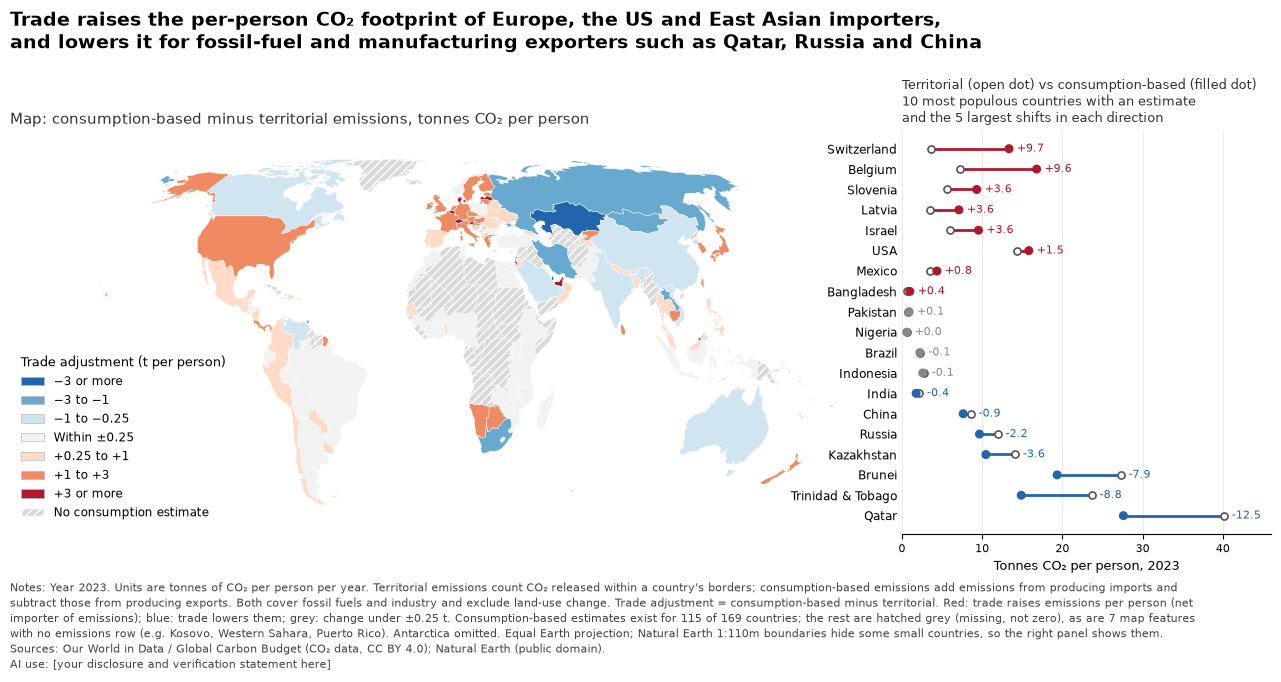

In [9]:
fig = plt.figure(figsize=(13, 6.9))
gs = fig.add_gridspec(1, 2, width_ratios=[2.35, 1], wspace=0.04,
                      left=0.01, right=0.98, top=0.80, bottom=0.215)

# Map
ax = fig.add_subplot(gs[0])
world.plot(column="diff", cmap=cmap, norm=norm, ax=ax, edgecolor="white", linewidth=0.3,
           missing_kwds={"color": "#d9d9d9", "hatch": "////", "edgecolor": "white", "linewidth": 0.3})
ax.set_axis_off()
ax.set_title("Map: consumption-based minus territorial emissions, tonnes CO₂ per person",
             loc="left", fontsize=10.5, color="#333333", pad=2)

handles = [Patch(facecolor=c, edgecolor="#bbbbbb", linewidth=0.5, label=l) for c, l in zip(colors, labels)]
handles.append(Patch(facecolor="#d9d9d9", hatch="////", edgecolor="white", label="No consumption estimate"))
ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.0, -0.02), fontsize=8.5, frameon=False,
          title="Trade adjustment (t per person)", title_fontsize=9, alignment="left")

# Right panel: territorial (open dot) vs consumption-based (filled dot)
bx = fig.add_subplot(gs[1])
y = np.arange(len(selected))
dot_colors = [colour_for(v) for v in selected["diff"]]
bx.hlines(y, selected["co2_per_capita"], selected["consumption_co2_per_capita"], colors=dot_colors, lw=2, zorder=2)
bx.scatter(selected["co2_per_capita"], y, s=26, facecolor="white", edgecolor="#555555", lw=1.2, zorder=3)
bx.scatter(selected["consumption_co2_per_capita"], y, s=30, color=dot_colors, zorder=4)
for yi, t, c, v, col in zip(y, selected["co2_per_capita"], selected["consumption_co2_per_capita"],
                            selected["diff"], dot_colors):
    bx.text(max(t, c) + 1.0, yi, f"{v:+.1f}", va="center", fontsize=8, color=col)

bx.set_yticks(y, selected["label"], fontsize=8.5)
bx.set_xlim(0, 46)
bx.set_xlabel("Tonnes CO₂ per person, 2023", fontsize=9)
bx.tick_params(axis="x", labelsize=8)
bx.tick_params(axis="y", length=0)
for side in ["top", "right", "left"]:
    bx.spines[side].set_visible(False)
bx.grid(axis="x", color="#e6e6e6", lw=0.6)
bx.set_axisbelow(True)
bx.set_title("Territorial (open dot) vs consumption-based (filled dot)\n"
             "10 most populous countries with an estimate\n"
             "and the 5 largest shifts in each direction",
             loc="left", fontsize=9, color="#333333")

# Title and notes
fig.suptitle("Trade raises the per-person CO₂ footprint of Europe, the US and East Asian importers,\n"
             "and lowers it for fossil-fuel and manufacturing exporters such as Qatar, Russia and China",
             x=0.01, y=0.975, ha="left", fontsize=13.5, fontweight="bold")

notes = (
    "Notes: Year 2023. Units are tonnes of CO₂ per person per year. Territorial emissions count CO₂ released within a country's "
    "borders; consumption-based emissions add emissions from producing imports and\nsubtract those from producing exports. "
    "Both cover fossil fuels and industry and exclude land-use change. Trade adjustment = consumption-based minus territorial. "
    "Red: trade raises emissions per person (net\nimporter of emissions); blue: trade lowers them; grey: change under ±0.25 t. "
    f"Consumption-based estimates exist for {len(with_estimate)} of {len(emissions)} countries; the rest are hatched grey "
    f"(missing, not zero), as are {len(unmatched)} map features\nwith no emissions row (e.g. Kosovo, Western Sahara, Puerto Rico). "
    "Antarctica omitted. Equal Earth projection; Natural Earth 1:110m boundaries hide some small countries, so the right panel shows them.\n"
    "Sources: Our World in Data / Global Carbon Budget (CO₂ data, CC BY 4.0); Natural Earth (public domain).\n"
    "AI use: [your disclosure and verification statement here]"
)
fig.text(0.01, 0.015, notes, fontsize=7.6, color="#444444", ha="left", va="bottom", linespacing=1.45)

fig.savefig("figures/submission.png", dpi=200)
plt.show()